In [ ]:
!pip install numpy==1.26.4

In [ ]:
!pip install captum


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 12.3 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os, random, time
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split



SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


VESSEL_ROOT = "/content/drive/MyDrive/Vessel_Merged"
META_CSV = os.path.join(VESSEL_ROOT, "metadata.csv")

assert os.path.exists(META_CSV), f"metadata.csv not found at: {META_CSV}"

df = pd.read_csv(META_CSV)

IMG_COL = "image"
MSK_COL = "mask"
SPLIT_COL = "split"

required_cols = [IMG_COL, MSK_COL, SPLIT_COL]

for col in required_cols:
    assert col in df.columns, f"{col} column missing in metadata.csv"


df[IMG_COL] = df[IMG_COL].apply(lambda x: os.path.join(VESSEL_ROOT, x))
df[MSK_COL] = df[MSK_COL].apply(lambda x: os.path.join(VESSEL_ROOT, x))


train_full_df = df[df[SPLIT_COL] == "train"].reset_index(drop=True)
test_df       = df[df[SPLIT_COL] == "test"].reset_index(drop=True)

train_df, val_df = train_test_split(
    train_full_df,
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print("Total samples :", len(df))
print("Train samples :", len(train_df))
print("Val samples   :", len(val_df))
print("Test samples  :", len(test_df))

Total samples : 48
Train samples : 30
Val samples   : 8
Test samples  : 10


In [ ]:
IMG_SIZE = 512
USE_CLAHE = True

def apply_clahe_rgb(pil_img):
    img = np.array(pil_img)
    img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l2 = clahe.apply(l)

    lab2 = cv2.merge([l2, a, b])

    bgr2 = cv2.cvtColor(lab2, cv2.COLOR_LAB2BGR)
    rgb2 = cv2.cvtColor(bgr2, cv2.COLOR_BGR2RGB)

    return Image.fromarray(rgb2)


class VesselDataset(Dataset):
    def __init__(self, df, img_size=512, use_clahe=True):
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.use_clahe = use_clahe

    def __len__(self):
        return len(self.df)

    def _load_rgb(self, path):
        img = Image.open(path)
        img = img.convert("RGB")

        if self.use_clahe:
            img = apply_clahe_rgb(img)

        img = img.resize(
            (self.img_size, self.img_size),
            Image.BILINEAR
        )

        arr = np.array(img).astype(np.float32) / 255.0
        arr = np.transpose(arr, (2, 0, 1))

        return torch.tensor(arr, dtype=torch.float32)

    def _load_mask(self, path):
        m = Image.open(path)
        m = m.convert("L")

        m = m.resize(
            (self.img_size, self.img_size),
            Image.NEAREST
        )

        arr = np.array(m).astype(np.float32)
        arr = (arr > 127).astype(np.float32)

        arr = np.expand_dims(arr, axis=0)

        return torch.tensor(arr, dtype=torch.float32)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, IMG_COL]
        msk_path = self.df.loc[idx, MSK_COL]

        x = self._load_rgb(img_path)
        y = self._load_mask(msk_path)

        return x, y



train_dataset = VesselDataset(
    train_df,
    img_size=IMG_SIZE,
    use_clahe=USE_CLAHE
)

val_dataset = VesselDataset(
    val_df,
    img_size=IMG_SIZE,
    use_clahe=USE_CLAHE
)

test_dataset = VesselDataset(
    test_df,
    img_size=IMG_SIZE,
    use_clahe=USE_CLAHE
)

print("Train dataset size :", len(train_dataset))
print("Val dataset size   :", len(val_dataset))
print("Test dataset size  :", len(test_dataset))

Train dataset size : 30
Val dataset size   : 8
Test dataset size  : 10


In [ ]:
BATCH = 2

def worker_init_fn(worker_id):
    np.random.seed(SEED + worker_id)
    random.seed(SEED + worker_id)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH,
    shuffle=True,
    num_workers=2,
    worker_init_fn=worker_init_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH,
    shuffle=False,
    num_workers=2,
    worker_init_fn=worker_init_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH,
    shuffle=False,
    num_workers=2,
    worker_init_fn=worker_init_fn
)

print("Train samples :", len(train_dataset))
print("Val samples   :", len(val_dataset))
print("Test samples  :", len(test_dataset))

print("Train batches :", len(train_loader))
print("Val batches   :", len(val_loader))
print("Test batches  :", len(test_loader))

Train samples : 30
Val samples   : 8
Test samples  : 10
Train batches : 15
Val batches   : 4
Test batches  : 5


Train Set selected indices: [3]


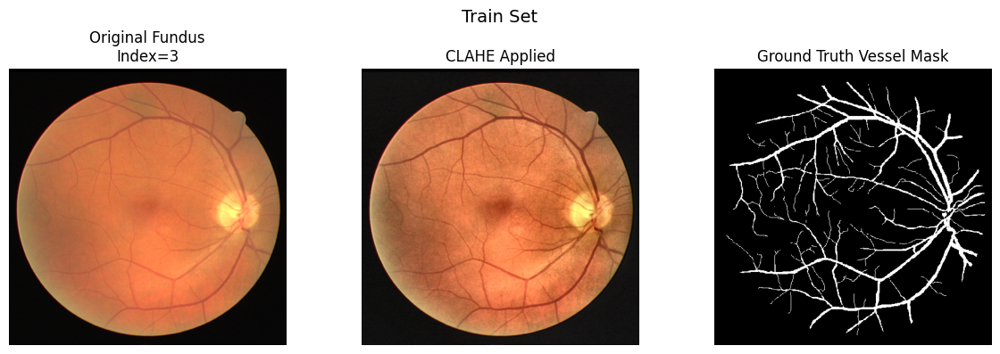

Validation Set selected indices: [4]


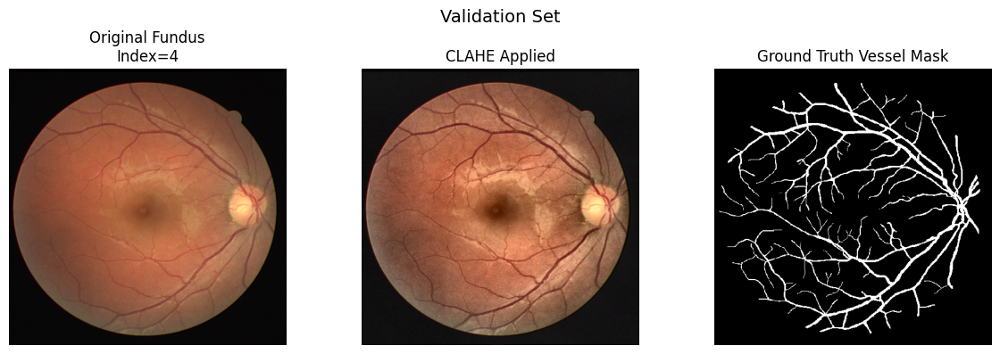

Test Set selected indices: [6]


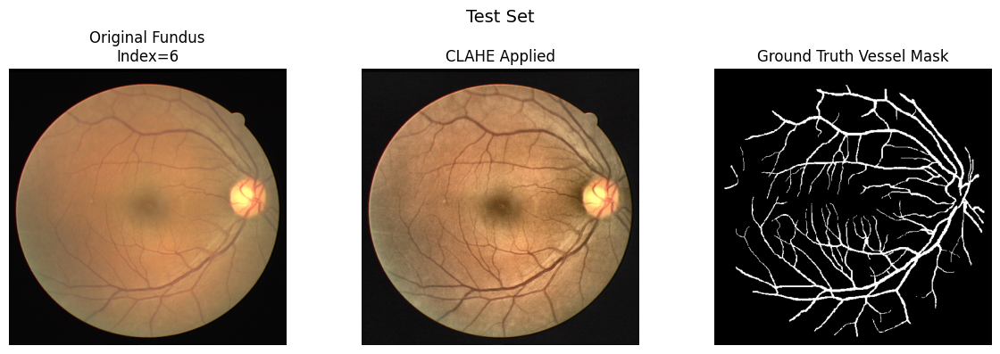

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def show_samples(loader, title="Samples", fixed_idx=None, n_random=1):

    dataset = loader.dataset
    total = len(dataset)

    # ==================================================
    # RANDOM SAMPLE SELECTION
    # ==================================================

    # indices = random.sample(
    #     range(total),
    #     min(n_random, total)
    # )

    # ==================================================
    # FIXED SAMPLE SELECTION
    # ==================================================

    indices = [fixed_idx]

    print(f"{title} selected indices:", indices)

    fig, axes = plt.subplots(len(indices), 3, figsize=(12, 4 * len(indices)))

    if len(indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(indices):

        if idx >= total:
            print(f"Index {idx} out of range for {title}")
            continue

        sample = dataset[idx]

        if isinstance(sample, (list, tuple)):
            x, y = sample

        elif isinstance(sample, dict):
            image_key = None
            mask_key = None

            for k in sample.keys():
                lk = k.lower()

                if image_key is None and lk in ["image", "images", "img", "x", "input"]:
                    image_key = k

                if mask_key is None and lk in ["mask", "masks", "y", "target", "label"]:
                    mask_key = k

            x = sample[image_key]
            y = sample[mask_key]

        else:
            raise ValueError(f"Unsupported sample type: {type(sample)}")

        # -----------------------------------------
        # Original Image
        # -----------------------------------------

        img_path = dataset.df.loc[idx, IMG_COL]

        original_img = Image.open(img_path).convert("RGB")

        original_img = original_img.resize(
            (IMG_SIZE, IMG_SIZE),
            Image.BILINEAR
        )

        original_img = np.array(original_img)

        # -----------------------------------------
        # CLAHE Image
        # -----------------------------------------

        clahe_img = np.transpose(
            x.numpy(),
            (1, 2, 0)
        )

        clahe_img = np.clip(
            clahe_img,
            0,
            1
        )

        # -----------------------------------------
        # Ground Truth Mask
        # -----------------------------------------

        gt_mask = y[0].numpy()

        axes[row, 0].imshow(original_img)
        axes[row, 0].set_title(
            f"Original Fundus\nIndex={idx}"
        )
        axes[row, 0].axis("off")

        axes[row, 1].imshow(clahe_img)
        axes[row, 1].set_title(
            "CLAHE Applied"
        )
        axes[row, 1].axis("off")

        axes[row, 2].imshow(
            gt_mask,
            cmap="gray"
        )

        axes[row, 2].set_title(
            "Ground Truth Vessel Mask"
        )

        axes[row, 2].axis("off")

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()




show_samples(
    train_loader,
    title="Train Set",
    fixed_idx=3
)

show_samples(
    val_loader,
    title="Validation Set",
    fixed_idx=4
)

show_samples(
    test_loader,
    title="Test Set",
    fixed_idx=6
)

# ==================================================
# RANDOM VERSION
# ==================================================

# show_samples(
#     train_loader,
#     title="Train Set",
#     n_random=1
# )
#
# show_samples(
#     val_loader,
#     title="Validation Set",
#     n_random=1
# )
#
# show_samples(
#     test_loader,
#     title="Test Set",
#     n_random=1
# )

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class AttentionGate(nn.Module):

    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class AttUNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=64):
        super().__init__()
        # Encoder
        self.enc1 = DoubleConv(in_ch, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base*2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = DoubleConv(base*4, base*8)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(base*8, base*16)

        # Decoder
        self.up4 = nn.ConvTranspose2d(base*16, base*8, 2, stride=2)
        self.att4 = AttentionGate(base*8, base*8, base*4)
        self.dec4 = DoubleConv(base*16, base*8)

        self.up3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2)
        self.att3 = AttentionGate(base*4, base*4, base*2)
        self.dec3 = DoubleConv(base*8, base*4)

        self.up2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2)
        self.att2 = AttentionGate(base*2, base*2, base)
        self.dec2 = DoubleConv(base*4, base*2)

        self.up1 = nn.ConvTranspose2d(base*2, base, 2, stride=2)
        self.att1 = AttentionGate(base, base, base//2)
        self.dec1 = DoubleConv(base*2, base)

        self.out = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))

        b = self.bottleneck(self.pool4(e4))

        d4 = self.up4(b)
        e4a = self.att4(d4, e4)
        d4 = self.dec4(torch.cat([d4, e4a], dim=1))

        d3 = self.up3(d4)
        e3a = self.att3(d3, e3)
        d3 = self.dec3(torch.cat([d3, e3a], dim=1))

        d2 = self.up2(d3)
        e2a = self.att2(d2, e2)
        d2 = self.dec2(torch.cat([d2, e2a], dim=1))

        d1 = self.up1(d2)
        e1a = self.att1(d1, e1)
        d1 = self.dec1(torch.cat([d1, e1a], dim=1))

        return self.out(d1)

seg_model = AttUNet(in_ch=3, out_ch=1, base=64).to(device)
print(seg_model.__class__.__name__, " ready")


AttUNet  ready


In [ ]:
THR = 0.50

def dice_coeff(pred, target, eps=1e-7):
    pred = pred.reshape(-1)
    target = target.reshape(-1)
    inter = (pred * target).sum()
    return (2 * inter + eps) / (pred.sum() + target.sum() + eps)

def iou_coeff(pred, target, eps=1e-7):
    pred = pred.reshape(-1)
    target = target.reshape(-1)
    inter = (pred * target).sum()
    union = pred.sum() + target.sum() - inter
    return (inter + eps) / (union + eps)

def pixel_acc(pred, target):
    return (pred == target).float().mean().item()


def weighted_bce_loss_with_logits(logits, targets, pos_weight=5.0):
    pw = torch.tensor([pos_weight], dtype=logits.dtype, device=logits.device)
    return F.binary_cross_entropy_with_logits(logits, targets, pos_weight=pw)

def dice_loss_from_logits(logits, targets, eps=1e-6):
    probs = torch.sigmoid(logits)
    probs = probs.view(probs.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    inter = (probs * targets).sum(dim=1)
    den = probs.sum(dim=1) + targets.sum(dim=1)

    dice = (2 * inter + eps) / (den + eps)
    return 1.0 - dice.mean()

def tversky_loss_from_logits(logits, targets, alpha=0.25, beta=0.75, eps=1e-6):

    probs = torch.sigmoid(logits)
    probs = probs.view(probs.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    tp = (probs * targets).sum(dim=1)
    fp = (probs * (1 - targets)).sum(dim=1)
    fn = ((1 - probs) * targets).sum(dim=1)

    tversky = (tp + eps) / (tp + alpha * fp + beta * fn + eps)
    return 1.0 - tversky.mean()

def edge_loss_from_logits(logits, targets):

    probs = torch.sigmoid(logits)

    sobel_x = torch.tensor(
        [[1, 0, -1],
         [2, 0, -2],
         [1, 0, -1]], dtype=torch.float32, device=logits.device
    ).view(1, 1, 3, 3)

    sobel_y = torch.tensor(
        [[1, 2, 1],
         [0, 0, 0],
         [-1, -2, -1]], dtype=torch.float32, device=logits.device
    ).view(1, 1, 3, 3)

    p_dx = F.conv2d(probs, sobel_x, padding=1)
    p_dy = F.conv2d(probs, sobel_y, padding=1)
    t_dx = F.conv2d(targets, sobel_x, padding=1)
    t_dy = F.conv2d(targets, sobel_y, padding=1)

    p_edge = torch.sqrt(p_dx ** 2 + p_dy ** 2 + 1e-7)
    t_edge = torch.sqrt(t_dx ** 2 + t_dy ** 2 + 1e-7)

    return F.l1_loss(p_edge, t_edge)

def connectivity_loss_from_logits(logits, targets):

    probs = torch.sigmoid(logits)

    avg_kernel = torch.ones((1, 1, 3, 3), dtype=torch.float32, device=logits.device) / 9.0
    p_smooth = F.conv2d(probs, avg_kernel, padding=1)
    t_smooth = F.conv2d(targets, avg_kernel, padding=1)

    return F.l1_loss(p_smooth, t_smooth)

def total_loss(
    logits,
    targets,
    w_bce=0.30,
    w_dice=0.20,
    w_tversky=0.30,
    w_edge=0.10,
    w_conn=0.10
):

    lb = weighted_bce_loss_with_logits(logits, targets, pos_weight=5.0)
    ld = dice_loss_from_logits(logits, targets)
    lt = tversky_loss_from_logits(logits, targets, alpha=0.25, beta=0.75)
    le = edge_loss_from_logits(logits, targets)
    lc = connectivity_loss_from_logits(logits, targets)

    return w_bce * lb + w_dice * ld + w_tversky * lt + w_edge * le + w_conn * lc

Epoch 1/100 | TrainLoss=0.6665 | ValLoss=0.7340 | ValDice=0.0000 | ValIoU=0.0000 | ValAcc=0.9279
Best model updated and saved to disk: stage2_attunet_best.pth


Epoch 2/100 | TrainLoss=0.5526 | ValLoss=0.7182 | ValDice=0.0000 | ValIoU=0.0000 | ValAcc=0.9279


Epoch 3/100 | TrainLoss=0.5131 | ValLoss=0.6174 | ValDice=0.4266 | ValIoU=0.2739 | ValAcc=0.9439
Best model updated and saved to disk: stage2_attunet_best.pth


Epoch 4/100 | TrainLoss=0.4887 | ValLoss=0.5139 | ValDice=0.6581 | ValIoU=0.4909 | ValAcc=0.9507
Best model updated and saved to disk: stage2_attunet_best.pth


Epoch 5/100 | TrainLoss=0.4708 | ValLoss=0.4802 | ValDice=0.7023 | ValIoU=0.5415 | ValAcc=0.9527
Best model updated and saved to disk: stage2_attunet_best.pth


Epoch 6/100 | TrainLoss=0.4571 | ValLoss=0.4653 | ValDice=0.6913 | ValIoU=0.5294 | ValAcc=0.9465


... (91 outputs left out)

Epoch 98/100 | TrainLoss=0.1424 | ValLoss=0.3304 | ValDice=0.7705 | ValIoU=0.6269 | ValAcc=0.9688


Epoch 99/100 | TrainLoss=0.1423 | ValLoss=0.3306 | ValDice=0.7704 | ValIoU=0.6268 | ValAcc=0.9687


Epoch 100/100 | TrainLoss=0.1420 | ValLoss=0.3301 | ValDice=0.7705 | ValIoU=0.6268 | ValAcc=0.9687

Training complete.
Best Val Dice : 0.7847543954849243
Best epoch    : 34
Saved model   : stage2_attunet_best.pth
Verified: model file exists.



========== TEST RESULTS ==========
Test Loss : 0.3258
Test Dice : 0.7816
Test IoU  : 0.6417
Test Acc  : 0.9630

========== CONFUSION MATRIX ==========
TN = 2349863
FP = 50367
FN = 46688
TP = 174522

Sensitivity / Recall : 0.7889
Specificity          : 0.9790
Precision            : 0.7760


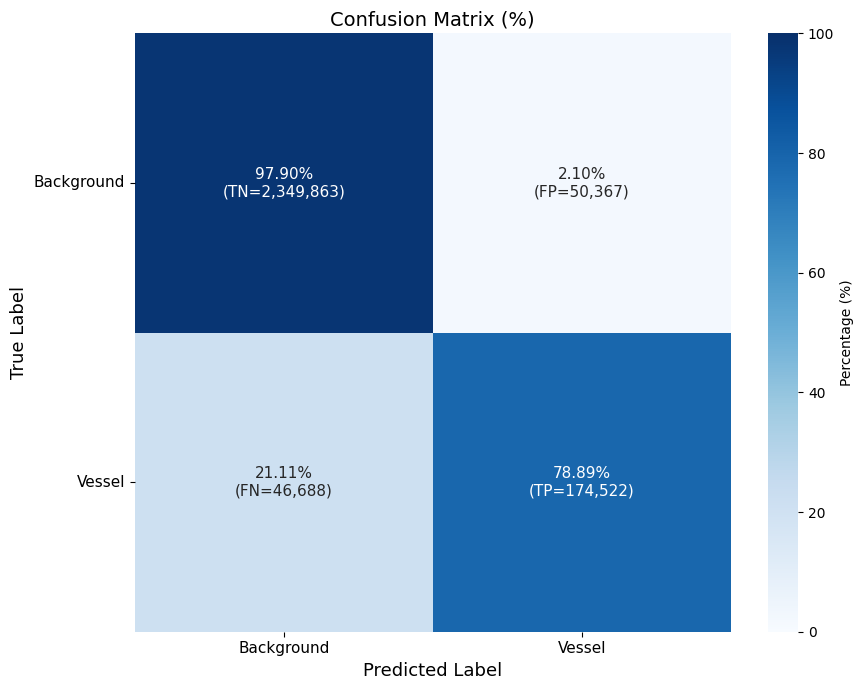

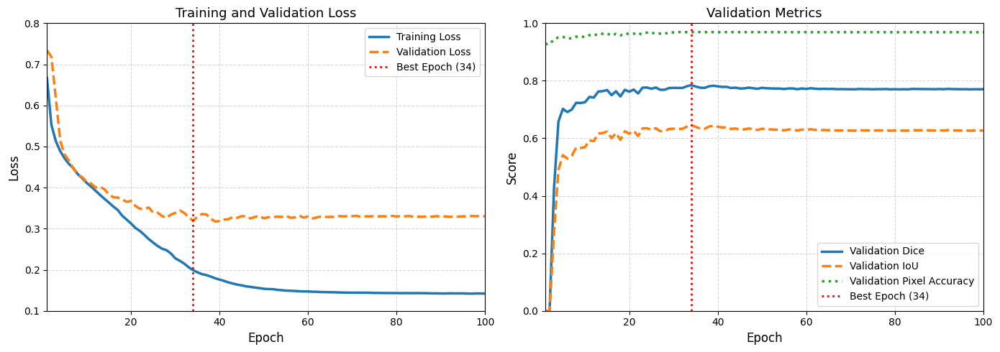

In [ ]:
from tqdm import tqdm
import numpy as np
import torch
import matplotlib.pyplot as plt
import os
from sklearn.metrics import confusion_matrix
import seaborn as sns

EPOCHS = 100
LR = 1e-4
SAVE_PATH = "stage2_attunet_best.pth"

optimizer = torch.optim.AdamW(
    seg_model.parameters(),
    lr=LR,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=6,
    min_lr=1e-6
)

history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": [],
    "val_acc": []
}

best_dice = -1.0
best_state = None
best_epoch = -1


for epoch in range(1, EPOCHS + 1):

    seg_model.train()
    train_loss = 0.0

    for x, y in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=False):
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = seg_model(x)
        loss = total_loss(logits, y)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(seg_model.parameters(), max_norm=1.0)

        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(train_loader)

    seg_model.eval()
    val_loss = 0.0
    dice_list, iou_list, acc_list = [], [], []

    with torch.no_grad():
        for x, y in tqdm(val_loader, desc=f"Epoch {epoch}/{EPOCHS} [Val]", leave=False):
            x = x.to(device)
            y = y.to(device)

            logits = seg_model(x)
            loss = total_loss(logits, y)
            val_loss += loss.item()

            probs = torch.sigmoid(logits)
            pred = (probs > THR).float()

            dice_list.append(dice_coeff(pred, y).item())
            iou_list.append(iou_coeff(pred, y).item())
            acc_list.append(pixel_acc(pred, y))

    val_loss /= len(val_loader)

    v_dice = float(np.mean(dice_list))
    v_iou = float(np.mean(iou_list))
    v_acc = float(np.mean(acc_list))

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(v_dice)
    history["val_iou"].append(v_iou)
    history["val_acc"].append(v_acc)

    scheduler.step(v_dice)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"TrainLoss={train_loss:.4f} | "
        f"ValLoss={val_loss:.4f} | "
        f"ValDice={v_dice:.4f} | "
        f"ValIoU={v_iou:.4f} | "
        f"ValAcc={v_acc:.4f}"
    )

    if v_dice > best_dice:
        best_dice = v_dice
        best_epoch = epoch

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in seg_model.state_dict().items()
        }

        torch.save(seg_model.state_dict(), SAVE_PATH)
        print(f"Best model updated and saved to disk: {SAVE_PATH}")


if best_state is not None:
    seg_model.load_state_dict(best_state)

print("\nTraining complete.")
print("Best Val Dice :", best_dice)
print("Best epoch    :", best_epoch)
print("Saved model   :", SAVE_PATH)

if os.path.exists(SAVE_PATH):
    print("Verified: model file exists.")
else:
    print("Warning: model file was not created.")


# ==========================================================
# TEST EVALUATION
# ==========================================================

seg_model.eval()

test_loss = 0.0
test_dice_list = []
test_iou_list = []
test_acc_list = []

all_gt = []
all_pred = []

with torch.no_grad():
    for x, y in tqdm(test_loader, desc="Test Evaluation", leave=False):
        x = x.to(device)
        y = y.to(device)

        logits = seg_model(x)
        loss = total_loss(logits, y)
        test_loss += loss.item()

        probs = torch.sigmoid(logits)
        pred = (probs > THR).float()

        test_dice_list.append(dice_coeff(pred, y).item())
        test_iou_list.append(iou_coeff(pred, y).item())
        test_acc_list.append(pixel_acc(pred, y))

        all_gt.extend(y.detach().cpu().numpy().astype(np.uint8).flatten())
        all_pred.extend(pred.detach().cpu().numpy().astype(np.uint8).flatten())

test_loss = test_loss / len(test_loader)

test_dice = float(np.mean(test_dice_list))
test_iou = float(np.mean(test_iou_list))
test_acc = float(np.mean(test_acc_list))

print("\n========== TEST RESULTS ==========")
print(f"Test Loss : {test_loss:.4f}")
print(f"Test Dice : {test_dice:.4f}")
print(f"Test IoU  : {test_iou:.4f}")
print(f"Test Acc  : {test_acc:.4f}")


# ==========================================================
# CONFUSION MATRIX
# ==========================================================

all_gt = np.array(all_gt)
all_pred = np.array(all_pred)

cm = confusion_matrix(
    all_gt,
    all_pred,
    labels=[0, 1]
)

TN, FP, FN, TP = cm.ravel()

sensitivity = TP / (TP + FN + 1e-8)
specificity = TN / (TN + FP + 1e-8)
precision = TP / (TP + FP + 1e-8)

print("\n========== CONFUSION MATRIX ==========")
print("TN =", TN)
print("FP =", FP)
print("FN =", FN)
print("TP =", TP)

print("\nSensitivity / Recall :", f"{sensitivity:.4f}")
print("Specificity          :", f"{specificity:.4f}")
print("Precision            :", f"{precision:.4f}")


# ==========================================================
# NORMALIZED CONFUSION MATRIX (%) WITH RAW COUNTS
# ==========================================================

cm_percent = cm.astype(np.float64)
cm_percent = cm_percent / cm_percent.sum(axis=1, keepdims=True)
cm_percent = cm_percent * 100

labels = np.array([
    [
        f"{cm_percent[0, 0]:.2f}%\n(TN={TN:,})",
        f"{cm_percent[0, 1]:.2f}%\n(FP={FP:,})"
    ],
    [
        f"{cm_percent[1, 0]:.2f}%\n(FN={FN:,})",
        f"{cm_percent[1, 1]:.2f}%\n(TP={TP:,})"
    ]
])

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_percent,
    annot=labels,
    fmt="",
    cmap="Blues",
    xticklabels=["Background", "Vessel"],
    yticklabels=["Background", "Vessel"],
    vmin=0,
    vmax=100,
    annot_kws={"fontsize": 11},
    cbar_kws={"label": "Percentage (%)"}
)

plt.xlabel("Predicted Label", fontsize=13)
plt.ylabel("True Label", fontsize=13)

plt.title(
    "Confusion Matrix (%)",
    fontsize=14
)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11, rotation=0)

plt.tight_layout()
plt.show()


# ==========================================================
# TRAINING CURVES
# ==========================================================

epochs = np.arange(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    epochs,
    history["train_loss"],
    linewidth=2.5,
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    linewidth=2.5,
    linestyle="--",
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    color="red",
    linestyle=":",
    linewidth=2,
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Training and Validation Loss", fontsize=13)

plt.xlim(1, len(history["train_loss"]))
plt.ylim(0.10, 0.80)

plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)


plt.subplot(1, 2, 2)

plt.plot(
    epochs,
    history["val_dice"],
    linewidth=2.5,
    label="Validation Dice"
)

plt.plot(
    epochs,
    history["val_iou"],
    linewidth=2.5,
    linestyle="--",
    label="Validation IoU"
)

plt.plot(
    epochs,
    history["val_acc"],
    linewidth=2.5,
    linestyle=":",
    label="Validation Pixel Accuracy"
)

plt.axvline(
    best_epoch,
    color="red",
    linestyle=":",
    linewidth=2,
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.title("Validation Metrics", fontsize=13)

plt.xlim(1, len(history["train_loss"]))
plt.ylim(0.0, 1.0)

plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
for thr in [0.50, 0.45, 0.40, 0.35, 0.30]:
    all_gt = []
    all_pred = []

    dice_list = []
    iou_list = []

    seg_model.eval()

    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(device)
            y = y.to(device)

            logits = seg_model(x)
            probs = torch.sigmoid(logits)
            pred = (probs > thr).float()

            dice_list.append(dice_coeff(pred, y).item())
            iou_list.append(iou_coeff(pred, y).item())

            all_gt.extend(y.cpu().numpy().astype(np.uint8).flatten())
            all_pred.extend(pred.cpu().numpy().astype(np.uint8).flatten())

    cm = confusion_matrix(all_gt, all_pred, labels=[0, 1])
    TN, FP, FN, TP = cm.ravel()

    recall = TP / (TP + FN + 1e-8)
    precision = TP / (TP + FP + 1e-8)
    specificity = TN / (TN + FP + 1e-8)

    print(f"\nTHR = {thr}")
    print(f"Dice        : {np.mean(dice_list):.4f}")
    print(f"IoU         : {np.mean(iou_list):.4f}")
    print(f"FN          : {FN}")
    print(f"FP          : {FP}")
    print(f"Recall      : {recall:.4f}")
    print(f"Precision   : {precision:.4f}")
    print(f"Specificity : {specificity:.4f}")


THR = 0.5
Dice        : 0.7816
IoU         : 0.6417
FN          : 46688
FP          : 50367
Recall      : 0.7889
Precision   : 0.7760
Specificity : 0.9790

THR = 0.45
Dice        : 0.7813
IoU         : 0.6412
FN          : 45109
FP          : 53044
Recall      : 0.7961
Precision   : 0.7685
Specificity : 0.9779

THR = 0.4
Dice        : 0.7808
IoU         : 0.6406
FN          : 43458
FP          : 55871
Recall      : 0.8035
Precision   : 0.7608
Specificity : 0.9767

THR = 0.35
Dice        : 0.7799
IoU         : 0.6393
FN          : 41780
FP          : 59058
Recall      : 0.8111
Precision   : 0.7524
Specificity : 0.9754

THR = 0.3
Dice        : 0.7786
IoU         : 0.6377
FN          : 39730
FP          : 63000
Recall      : 0.8204
Precision   : 0.7423
Specificity : 0.9738


In [ ]:
import os, shutil

# Create Drive folder
SAVE_DIR = "/content/drive/MyDrive/DR_Project/stage2/weights"
os.makedirs(SAVE_DIR, exist_ok=True)

LOCAL_FILE = "stage2_attunet_best.pth"

if os.path.exists(LOCAL_FILE):
    DEST_FILE = os.path.join(SAVE_DIR, "stage2_attunet_best.pth")
    shutil.copy(LOCAL_FILE, DEST_FILE)
    print("Stage 2 model saved to Drive:")
    print(DEST_FILE)
else:
    print("best_model.pth not found. Run training first.")

Stage 2 model saved to Drive:
/content/drive/MyDrive/DR_Project/stage2/weights/stage2_attunet_best.pth


Sample 1 | Index=9 | Prediction Score=0.8645 | Dice=0.7819 | IoU=0.6419
Sample 2 | Index=4 | Prediction Score=0.8355 | Dice=0.7994 | IoU=0.6658
Sample 3 | Index=2 | Prediction Score=0.8137 | Dice=0.7828 | IoU=0.6431


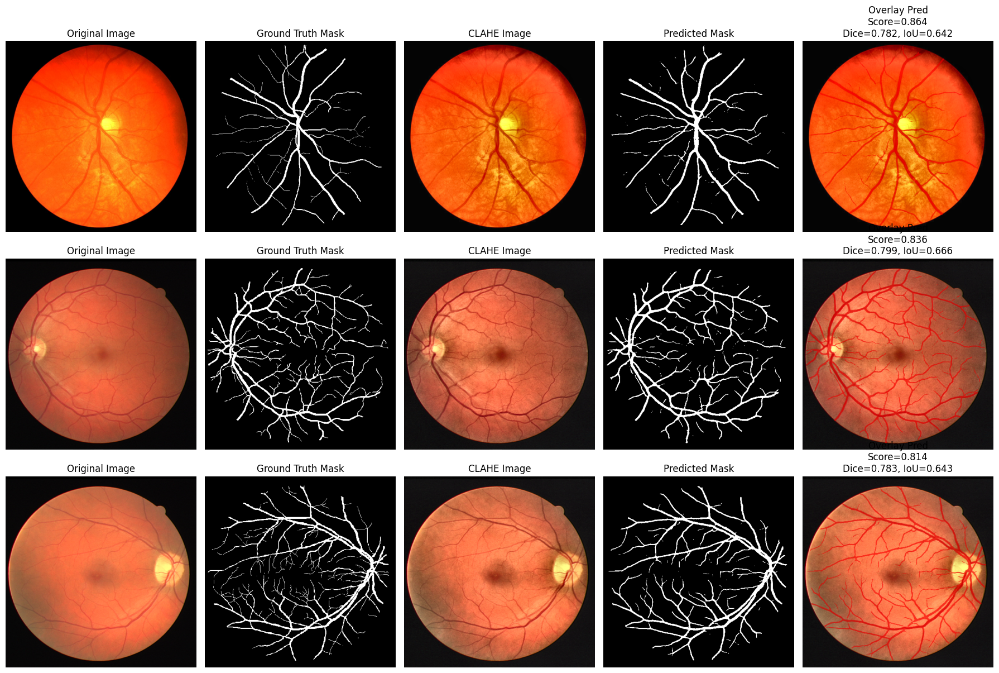

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image

def overlay_mask(img_rgb, mask01, alpha=0.55):
    img = np.clip(img_rgb, 0, 1)
    img = (img * 255).astype(np.uint8).copy()

    red = np.zeros_like(img)
    red[..., 0] = 255

    m = (mask01 > 0.5).astype(np.uint8)

    blended = img.copy()
    blended[m == 1] = (
        alpha * red[m == 1] + (1 - alpha) * img[m == 1]
    ).astype(np.uint8)

    return blended


def get_sample_from_dataset(dataset, idx):
    sample = dataset[idx]

    if isinstance(sample, (list, tuple)):
        x, y = sample

    elif isinstance(sample, dict):
        image_key = None
        mask_key = None

        for k in sample.keys():
            lk = k.lower()

            if image_key is None and lk in ["image", "images", "img", "x", "input"]:
                image_key = k

            if mask_key is None and lk in ["mask", "masks", "y", "target", "label"]:
                mask_key = k

        if image_key is None or mask_key is None:
            raise ValueError(
                f"Could not find image/mask keys in dataset sample: {list(sample.keys())}"
            )

        x = sample[image_key]
        y = sample[mask_key]

    else:
        raise ValueError(f"Unsupported dataset sample type: {type(sample)}")

    return x, y


def load_original_image(dataset, idx):
    img_path = dataset.df.loc[idx, IMG_COL]

    original_img = Image.open(img_path).convert("RGB")

    original_img = original_img.resize(
        (IMG_SIZE, IMG_SIZE),
        Image.BILINEAR
    )

    original_img = np.array(original_img).astype(np.float32) / 255.0

    return np.clip(original_img, 0, 1)


def show_high_score_test_predictions(n=3):
    seg_model.eval()

    dataset = test_loader.dataset
    total = len(dataset)

    if total == 0:
        print("Test dataset is empty.")
        return

    scored_samples = []

    with torch.no_grad():
        for idx in range(total):
            x, y = get_sample_from_dataset(dataset, idx)

            x_batch = x.unsqueeze(0).to(device)
            y_batch = y.unsqueeze(0).to(device)

            logits = seg_model(x_batch)
            probs = torch.sigmoid(logits)
            pred = (probs > THR).float()

            gt_pixels = (y_batch > 0.5).float()

            prediction_score = (
                (probs * gt_pixels).sum() / (gt_pixels.sum() + 1e-8)
            ).item()

            dice_val = dice_coeff(pred, y_batch).item()
            iou_val = iou_coeff(pred, y_batch).item()

            scored_samples.append({
                "idx": idx,
                "prediction_score": prediction_score,
                "dice": dice_val,
                "iou": iou_val,
                "x": x.detach().cpu(),
                "y": y.detach().cpu(),
                "pred": pred.detach().cpu()
            })

    scored_samples = sorted(
        scored_samples,
        key=lambda d: d["prediction_score"],
        reverse=True
    )

    selected = scored_samples[:min(n, len(scored_samples))]

    for i, item in enumerate(selected, start=1):
        print(
            f"Sample {i} | "
            f"Index={item['idx']} | "
            f"Prediction Score={item['prediction_score']:.4f} | "
            f"Dice={item['dice']:.4f} | "
            f"IoU={item['iou']:.4f}"
        )

    fig, axes = plt.subplots(
        len(selected),
        5,
        figsize=(18, 4 * len(selected))
    )

    if len(selected) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, item in enumerate(selected):
        idx = item["idx"]

        x = item["x"]
        y = item["y"]
        pred = item["pred"]

        original_img = load_original_image(dataset, idx)

        clahe_img = np.transpose(
            x.numpy(),
            (1, 2, 0)
        )
        clahe_img = np.clip(clahe_img, 0, 1)

        gt = y[0].numpy()
        pr = pred[0, 0].numpy()

        axes[row, 0].imshow(original_img)
        axes[row, 0].set_title("Original Image")

        axes[row, 1].imshow(gt, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title("Ground Truth Mask")

        axes[row, 2].imshow(clahe_img)
        axes[row, 2].set_title("CLAHE Image")

        axes[row, 3].imshow(pr, cmap="gray", vmin=0, vmax=1)
        axes[row, 3].set_title("Predicted Mask")

        axes[row, 4].imshow(overlay_mask(clahe_img, pr))
        axes[row, 4].set_title(
            f"Overlay Pred\n"
            f"Score={item['prediction_score']:.3f}\n"
            f"Dice={item['dice']:.3f}, IoU={item['iou']:.3f}"
        )

        for j in range(5):
            axes[row, j].axis("off")

    plt.tight_layout()
    plt.show()


show_high_score_test_predictions(n=3)

In [ ]:
import gc, os, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import cv2

from captum.attr import (
    Saliency,
    IntegratedGradients,
    Occlusion,
    LayerGradCam,
    GuidedBackprop,
    NoiseTunnel
)

try:
    from captum.attr import LRP
    HAS_LRP = True
except Exception:
    HAS_LRP = False
    print(" LRP is not available in this Captum runtime.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(" Device:", device)


 Device: cuda


In [ ]:
import numpy
print(numpy.__version__)

1.26.4


In [ ]:
!pip install captum shap lime scikit-image -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 8.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.2 MB 61.6 MB/s eta 0:00:00


In [ ]:
import numpy
import captum
import shap
import lime
import skimage

print("numpy:", numpy.__version__)
print("captum ok")
print("shap ok")
print("lime ok")
print("skimage ok")

numpy: 1.26.4
captum ok
shap ok
lime ok
skimage ok


In [ ]:
import gc, torch

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

Selected from      : Test set
 Test index   : 4
Threshold          : 0.5
Prediction Score   : 0.835519
Dice               : 0.799397
IoU                : 0.665830

Running Saliency...
Saliency mean score        : 0.464418
Saliency active pixels     : 35223
Saliency active area ratio : 0.136452


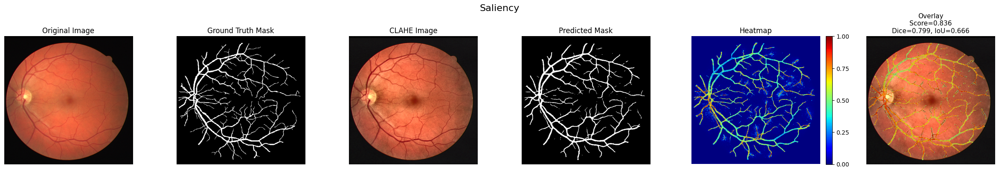


Running Grad-CAM...
Grad-CAM mean score        : 0.741763
Grad-CAM active pixels     : 25908
Grad-CAM active area ratio : 0.100366


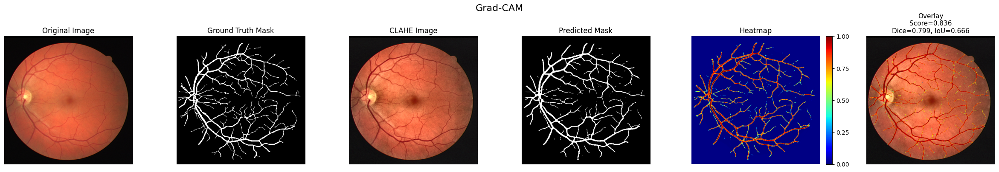


Running Integrated Gradients...
Integrated Gradients mean score        : 0.383224
Integrated Gradients active pixels     : 34131
Integrated Gradients active area ratio : 0.132222


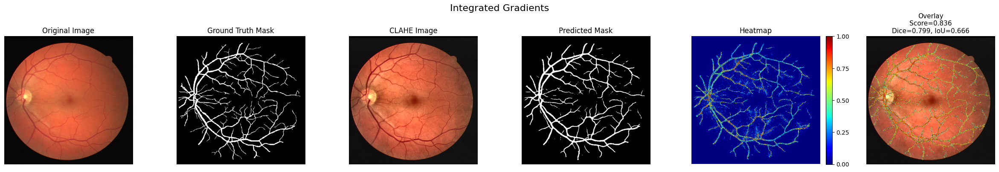


Running Occlusion...
Occlusion mean score        : 0.625332
Occlusion active pixels     : 28824
Occlusion active area ratio : 0.111663


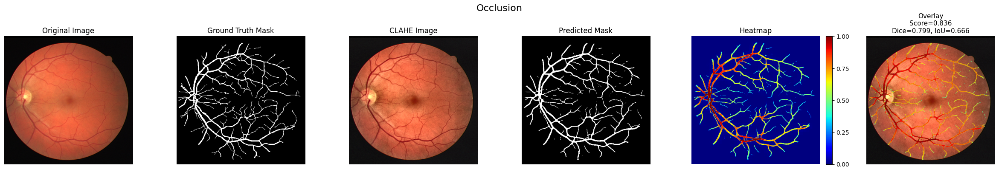


Running Guided Backprop...


/usr/local/lib/python3.12/dist-packages/captum/attr/_core/guided_backprop_deconvnet.py:66: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


Guided Backprop mean score        : 0.472961
Guided Backprop active pixels     : 27219
Guided Backprop active area ratio : 0.105445


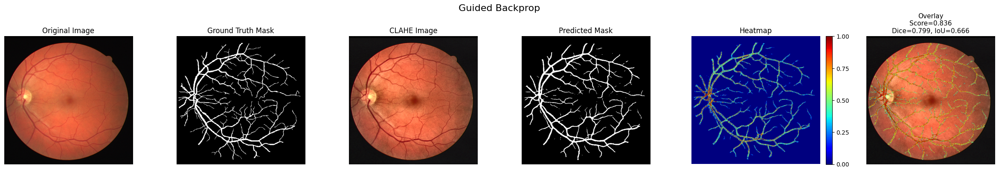


Running SmoothGrad...
SmoothGrad mean score        : 0.455794
SmoothGrad active pixels     : 22828
SmoothGrad active area ratio : 0.088435


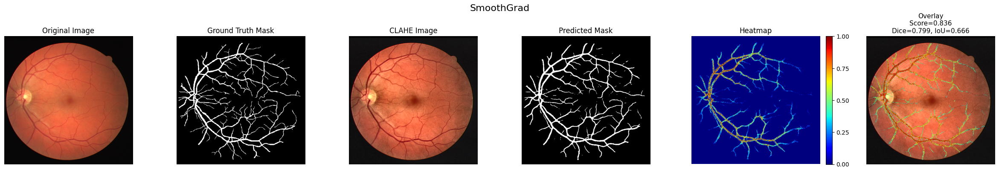


Running SHAP...
SHAP mean score        : 0.616518
SHAP active pixels     : 28773
SHAP active area ratio : 0.111465


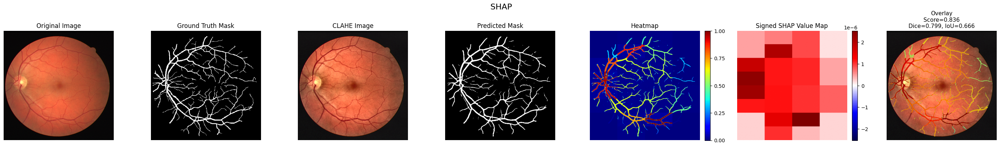


Running LIME...


  0%|          | 0/1000 [00:00<?, ?it/s]

LIME mean score        : 0.379371
LIME active pixels     : 26428
LIME active area ratio : 0.102381


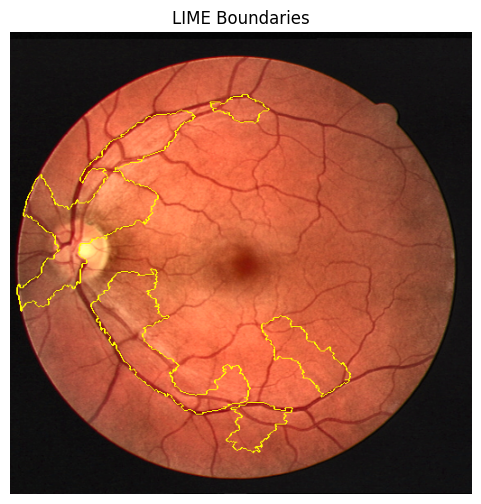

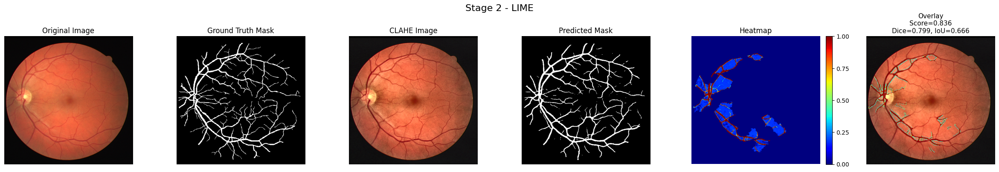

In [ ]:
import gc
import os
import cv2
import shap
import contextlib
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from PIL import Image

from captum.attr import (
    Saliency,
    IntegratedGradients,
    LayerGradCam,
    LayerAttribution,
    GuidedBackprop,
    NoiseTunnel
)

from lime import lime_image
from skimage.segmentation import mark_boundaries



seg_model = seg_model.to(device).eval()

THR = 0.50
TEST_INDEX = 4

IG_STEPS = 6
IG_BATCH = 1

SMOOTH_SAMPLES = 6
SMOOTH_BATCH = 1

OCC_WINDOW = 24
OCC_STRIDE = 12

SHAP_MAX_EVALS = 300
LIME_NUM_SAMPLES = 1000

OVERLAY_ALPHA = 0.80



@contextlib.contextmanager
def suppress_output():
    with open(os.devnull, "w") as fnull:
        with contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
            yield


try:
    shap.disable_progressbar()
except Exception:
    pass


def clear_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def normalize_map(arr):
    arr = np.asarray(arr, dtype=np.float32)
    arr = np.nan_to_num(arr)

    arr = arr - arr.min()
    mx = arr.max()

    if mx > 0:
        arr = arr / (mx + 1e-8)

    return arr.astype(np.float32)


def get_sample_from_dataset(dataset, idx):
    sample = dataset[idx]

    if isinstance(sample, (list, tuple)):
        return sample

    if isinstance(sample, dict):
        image_key = None
        mask_key = None

        for k in sample.keys():
            lk = k.lower()

            if image_key is None and lk in ["image", "images", "img", "x", "input"]:
                image_key = k

            if mask_key is None and lk in ["mask", "masks", "y", "target", "label"]:
                mask_key = k

        if image_key is None or mask_key is None:
            raise ValueError(f"Could not find image/mask keys: {list(sample.keys())}")

        return sample[image_key], sample[mask_key]

    raise ValueError(f"Unsupported sample type: {type(sample)}")


def load_original_image(dataset, idx, size=IMG_SIZE):
    img_path = dataset.df.loc[idx, IMG_COL]

    img = Image.open(img_path).convert("RGB")
    img = img.resize((size, size), Image.BILINEAR)

    img = np.array(img).astype(np.float32) / 255.0
    return np.clip(img, 0, 1)


def tensor_to_rgb01(x):
    img = x.detach().cpu()[0].permute(1, 2, 0).numpy()
    return np.clip(img, 0, 1)


def mask_to_np(y):
    return y.detach().cpu()[0, 0].numpy().astype(np.float32)


def make_fov_mask(img_rgb):
    gray = img_rgb.mean(axis=2)
    mask = gray > 0.03
    return mask.astype(np.float32)


def standardize_heatmap(raw_map, fov_mask):
    raw_map = normalize_map(raw_map)
    raw_map = raw_map * fov_mask

    vals = raw_map[fov_mask > 0]

    if vals.size > 0:
        p2 = np.percentile(vals, 2)
        p99 = np.percentile(vals, 99.5)

        raw_map = np.clip(raw_map, p2, p99)
        raw_map = normalize_map(raw_map)

        # Keep blue background but boost important regions
        raw_map = raw_map ** 1.10
        high = raw_map >= raw_map.mean()
        raw_map[high] = np.sqrt(raw_map[high])

    raw_map[fov_mask == 0] = 0.0

    return raw_map.astype(np.float32)


def otsu_active_mask(heatmap, fov_mask):
    heatmap = standardize_heatmap(heatmap, fov_mask)

    vals = heatmap[fov_mask > 0]

    if vals.size == 0:
        return np.zeros_like(heatmap, dtype=bool)

    vals_uint8 = (vals * 255).astype(np.uint8)

    otsu_thr, _ = cv2.threshold(
        vals_uint8,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    threshold = otsu_thr / 255.0

    active = (heatmap >= threshold) & (fov_mask > 0)

    return active


def make_overlay(img_rgb, heatmap, pred_np, fov_mask, alpha=OVERLAY_ALPHA):
    img_rgb = np.clip(img_rgb, 0, 1)
    heatmap = standardize_heatmap(heatmap, fov_mask)


    active_xai = otsu_active_mask(heatmap, fov_mask)


    pred_bin = (pred_np > 0.5).astype(np.uint8)
    kernel = np.ones((5, 5), np.uint8)
    pred_dilated = cv2.dilate(pred_bin, kernel, iterations=1).astype(bool)

    active = active_xai & pred_dilated & (fov_mask > 0)

    heat_uint8 = (heatmap * 255).astype(np.uint8)

    heat = cv2.applyColorMap(
        heat_uint8,
        cv2.COLORMAP_JET
    )

    heat = cv2.cvtColor(
        heat,
        cv2.COLOR_BGR2RGB
    ).astype(np.float32) / 255.0

    overlay = img_rgb.copy()

    overlay[active] = (
        (1 - alpha) * img_rgb[active] +
        alpha * heat[active]
    )

    return np.clip(overlay, 0, 1)


def print_stats(name, heatmap, fov_mask):
    heatmap = standardize_heatmap(heatmap, fov_mask)

    active = otsu_active_mask(heatmap, fov_mask)

    active_pixels = int(active.sum())
    fov_pixels = int((fov_mask > 0).sum())

    active_area_ratio = active_pixels / (fov_pixels + 1e-8)

    if active_pixels > 0:
        mean_score = float(heatmap[active].mean())
    else:
        mean_score = 0.0


    print(f"{name} mean score        : {mean_score:.6f}")
    print(f"{name} active pixels     : {active_pixels}")
    print(f"{name} active area ratio : {active_area_ratio:.6f}")


def show_xai(
    title,
    original_rgb,
    clahe_rgb,
    gt,
    pred,
    heatmap,
    fov_mask,
    score,
    dice,
    iou,
    shap_value_map=None
):
    heatmap = standardize_heatmap(heatmap, fov_mask)

    overlay = make_overlay(
        clahe_rgb,
        heatmap,
        pred,
        fov_mask,
        alpha=OVERLAY_ALPHA
    )

    if shap_value_map is None:
        fig, ax = plt.subplots(1, 6, figsize=(24, 4))
    else:
        fig, ax = plt.subplots(1, 7, figsize=(28, 4))

    fig.suptitle(title, fontsize=16)

    ax[0].imshow(original_rgb)
    ax[0].set_title("Original Image")
    ax[0].axis("off")

    ax[1].imshow(gt, cmap="gray", vmin=0, vmax=1)
    ax[1].set_title("Ground Truth Mask")
    ax[1].axis("off")

    ax[2].imshow(clahe_rgb)
    ax[2].set_title("CLAHE Image")
    ax[2].axis("off")

    ax[3].imshow(pred, cmap="gray", vmin=0, vmax=1)
    ax[3].set_title("Predicted Mask")
    ax[3].axis("off")

    im = ax[4].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    ax[4].set_title("Heatmap")
    ax[4].axis("off")

    cb = fig.colorbar(
        im,
        ax=ax[4],
        fraction=0.046,
        pad=0.04
    )
    cb.set_ticks([0.00, 0.25, 0.50, 0.75, 1.00])

    if shap_value_map is not None:
        sv = np.asarray(shap_value_map, dtype=np.float32)
        sv = np.nan_to_num(sv)

        vmax = np.max(np.abs(sv)) + 1e-12

        im2 = ax[5].imshow(
            sv,
            cmap="seismic",
            vmin=-vmax,
            vmax=vmax
        )
        ax[5].set_title("Signed SHAP Value Map")
        ax[5].axis("off")

        fig.colorbar(
            im2,
            ax=ax[5],
            fraction=0.046,
            pad=0.04
        )

        ax[6].imshow(overlay)
        ax[6].set_title(
            f"Overlay\nScore={score:.3f}\nDice={dice:.3f}, IoU={iou:.3f}",
            fontsize=11
        )
        ax[6].axis("off")

    else:
        ax[5].imshow(overlay)
        ax[5].set_title(
            f"Overlay\nScore={score:.3f}\nDice={dice:.3f}, IoU={iou:.3f}",
            fontsize=11
        )
        ax[5].axis("off")

    plt.tight_layout()
    plt.show()



def attr_to_positive_map(attr):
    a = attr.detach().cpu()
    a = torch.relu(a)

    if a.dim() != 4:
        raise ValueError(f"Unexpected attribution shape: {tuple(a.shape)}")

    if a.size(1) == 3:
        a = a.mean(dim=1)[0]
    else:
        a = a[0, 0]

    out = normalize_map(a.numpy())

    if out.max() == 0:
        return attr_to_abs_map(attr)

    return out


def attr_to_abs_map(attr):
    a = attr.detach().cpu()

    if a.dim() != 4:
        raise ValueError(f"Unexpected attribution shape: {tuple(a.shape)}")

    if a.size(1) == 3:
        a = a.abs().mean(dim=1)[0]
    else:
        a = a.abs()[0, 0]

    return normalize_map(a.numpy())


def focus_on_prediction(raw_map, prob_np, fov_mask):
    raw_map = normalize_map(raw_map)
    prob_np = normalize_map(prob_np)

    focused = raw_map * prob_np * fov_mask

    return normalize_map(focused)


dataset = test_loader.dataset

x, y = get_sample_from_dataset(dataset, TEST_INDEX)

x = x.unsqueeze(0).to(device)
y = y.unsqueeze(0).to(device)

x_xai = x
gt_mask = (y.float() > 0.5).float()

with torch.no_grad():
    logits = seg_model(x_xai)
    probs = torch.sigmoid(logits)
    pred_mask = (probs > THR).float()

    prediction_score = (
        (probs * gt_mask).sum() /
        (gt_mask.sum() + 1e-8)
    ).item()

    dice_value = dice_coeff(pred_mask, gt_mask).item()
    iou_value = iou_coeff(pred_mask, gt_mask).item()

original_np = load_original_image(dataset, TEST_INDEX, size=IMG_SIZE)
clahe_np = tensor_to_rgb01(x_xai)
gt_np = mask_to_np(gt_mask)
pred_np = mask_to_np(pred_mask)
prob_np = probs.detach().cpu()[0, 0].numpy()

fov_mask = make_fov_mask(clahe_np)


print("Selected from      : Test set")
print(" Test index   :", TEST_INDEX)
print("Threshold          :", THR)
print("Prediction Score   :", f"{prediction_score:.6f}")
print("Dice               :", f"{dice_value:.6f}")
print("IoU                :", f"{iou_value:.6f}")



class SegToScalarGT(nn.Module):
    def __init__(self, seg_model):
        super().__init__()
        self.seg_model = seg_model

    def forward(self, x, gt_mask):
        logits = self.seg_model(x)
        probs = torch.sigmoid(logits)

        score = (
            (probs * gt_mask).sum(dim=(1, 2, 3)) /
            (gt_mask.sum(dim=(1, 2, 3)) + 1e-8)
        )

        return score


scalar_model = SegToScalarGT(seg_model).to(device).eval()


# ==========================================================
# SALIENCY
# ==========================================================

print("\nRunning Saliency...")
clear_memory()

x_sal = x_xai.detach().clone().requires_grad_(True)

sal = Saliency(scalar_model)

sal_attr = sal.attribute(
    x_sal,
    additional_forward_args=(gt_mask,)
)

sal_raw = attr_to_positive_map(sal_attr)
sal_map = focus_on_prediction(sal_raw, prob_np, fov_mask)

print_stats("Saliency", sal_map, fov_mask)

show_xai(
    "Saliency",
    original_np,
    clahe_np,
    gt_np,
    pred_np,
    sal_map,
    fov_mask,
    prediction_score,
    dice_value,
    iou_value
)

del sal_attr, x_sal, sal
clear_memory()


# ==========================================================
# GRAD-CAM
# ==========================================================

print("\nRunning Grad-CAM...")
clear_memory()


def find_gradcam_layer(model):
    convs = []

    for name, m in model.named_modules():
        if isinstance(m, nn.Conv2d):
            convs.append((name, m))

    for name, m in reversed(convs):
        if m.kernel_size != (1, 1):
            return m


    return convs[-1][1]


target_layer = find_gradcam_layer(seg_model)

cam = LayerGradCam(
    scalar_model,
    target_layer
)

x_cam = x_xai.detach().clone().requires_grad_(True)

cam_attr = cam.attribute(
    x_cam,
    additional_forward_args=(gt_mask,)
)

cam_attr = LayerAttribution.interpolate(
    cam_attr,
    x_cam.shape[-2:]
)

cam_raw = attr_to_positive_map(cam_attr)
cam_map = focus_on_prediction(cam_raw, prob_np, fov_mask)

print_stats("Grad-CAM", cam_map, fov_mask)

show_xai(
    "Grad-CAM",
    original_np,
    clahe_np,
    gt_np,
    pred_np,
    cam_map,
    fov_mask,
    prediction_score,
    dice_value,
    iou_value
)

del cam_attr, x_cam, cam
clear_memory()


# ==========================================================
# INTEGRATED GRADIENTS
# ==========================================================

print("\nRunning Integrated Gradients...")
clear_memory()

x_ig = x_xai.detach().clone().requires_grad_(True)

ig = IntegratedGradients(scalar_model)

baseline = torch.zeros_like(x_ig)

ig_attr = ig.attribute(
    x_ig,
    baselines=baseline,
    additional_forward_args=(gt_mask,),
    n_steps=IG_STEPS,
    internal_batch_size=IG_BATCH
)

ig_raw = attr_to_positive_map(ig_attr)
ig_map = focus_on_prediction(ig_raw, prob_np, fov_mask)

print_stats("Integrated Gradients", ig_map, fov_mask)

show_xai(
    "Integrated Gradients",
    original_np,
    clahe_np,
    gt_np,
    pred_np,
    ig_map,
    fov_mask,
    prediction_score,
    dice_value,
    iou_value
)

del ig_attr, x_ig, baseline, ig
clear_memory()



print("\nRunning Occlusion...")
clear_memory()


def custom_occlusion_map(x, gt_mask):
    with torch.no_grad():
        base_probs = torch.sigmoid(seg_model(x))
        base_score = (
            (base_probs * gt_mask).sum() /
            (gt_mask.sum() + 1e-8)
        ).item()

    _, _, h, w = x.shape

    occ_map = np.zeros((h, w), dtype=np.float32)
    count_map = np.zeros((h, w), dtype=np.float32)

    for yy in range(0, h - OCC_WINDOW + 1, OCC_STRIDE):
        for xx in range(0, w - OCC_WINDOW + 1, OCC_STRIDE):
            x_occ = x.clone()
            x_occ[:, :, yy:yy + OCC_WINDOW, xx:xx + OCC_WINDOW] = 0

            with torch.no_grad():
                probs_occ = torch.sigmoid(seg_model(x_occ))
                score = (
                    (probs_occ * gt_mask).sum() /
                    (gt_mask.sum() + 1e-8)
                ).item()

            drop = max(base_score - score, 0.0)

            occ_map[yy:yy + OCC_WINDOW, xx:xx + OCC_WINDOW] += drop
            count_map[yy:yy + OCC_WINDOW, xx:xx + OCC_WINDOW] += 1.0

            del x_occ
            clear_memory()

    occ_map = occ_map / (count_map + 1e-8)

    return normalize_map(occ_map)


occ_raw = custom_occlusion_map(x_xai, gt_mask)
occ_map = focus_on_prediction(occ_raw, prob_np, fov_mask)

print_stats("Occlusion", occ_map, fov_mask)

show_xai(
    "Occlusion",
    original_np,
    clahe_np,
    gt_np,
    pred_np,
    occ_map,
    fov_mask,
    prediction_score,
    dice_value,
    iou_value
)

clear_memory()


# ==========================================================
# GUIDED BACKPROP
# ==========================================================

print("\nRunning Guided Backprop...")
clear_memory()

x_gb = x_xai.detach().clone().requires_grad_(True)

gb = GuidedBackprop(scalar_model)

gb_attr = gb.attribute(
    x_gb,
    additional_forward_args=(gt_mask,)
)

gb_raw = attr_to_positive_map(gb_attr)
gb_map = focus_on_prediction(gb_raw, prob_np, fov_mask)

print_stats("Guided Backprop", gb_map, fov_mask)

show_xai(
    "Guided Backprop",
    original_np,
    clahe_np,
    gt_np,
    pred_np,
    gb_map,
    fov_mask,
    prediction_score,
    dice_value,
    iou_value
)

del gb_attr, x_gb, gb
clear_memory()


# ==========================================================
# SMOOTHGRAD
# ==========================================================

print("\nRunning SmoothGrad...")
clear_memory()

x_sg = x_xai.detach().clone().requires_grad_(True)

nt = NoiseTunnel(
    GuidedBackprop(scalar_model)
)

sg_attr = nt.attribute(
    x_sg,
    additional_forward_args=(gt_mask,),
    nt_type="smoothgrad",
    stdevs=0.10,
    nt_samples=SMOOTH_SAMPLES,
    nt_samples_batch_size=SMOOTH_BATCH
)

sg_raw = attr_to_positive_map(sg_attr)
sg_map = focus_on_prediction(sg_raw, prob_np, fov_mask)

print_stats("SmoothGrad", sg_map, fov_mask)

show_xai(
    "SmoothGrad",
    original_np,
    clahe_np,
    gt_np,
    pred_np,
    sg_map,
    fov_mask,
    prediction_score,
    dice_value,
    iou_value
)

del sg_attr, x_sg, nt
clear_memory()


# ==========================================================
# SHAP
# ==========================================================

print("\nRunning SHAP...")
clear_memory()


def shap_predict_fn(images_np):
    batch = []

    for img_arr in images_np:
        if img_arr.max() > 1.0:
            img_arr = img_arr.astype(np.float32) / 255.0
        else:
            img_arr = img_arr.astype(np.float32)

        img_arr = np.clip(img_arr, 0, 1)

        img_t = torch.tensor(
            img_arr,
            dtype=torch.float32
        ).permute(2, 0, 1)

        batch.append(img_t)

    batch = torch.stack(batch).to(device)

    gt_rep = gt_mask.repeat(
        batch.size(0),
        1,
        1,
        1
    )

    with torch.no_grad():
        logits = seg_model(batch)
        probs_batch = torch.sigmoid(logits)

        score = (
            (probs_batch * gt_rep).sum(dim=(1, 2, 3)) /
            (gt_rep.sum(dim=(1, 2, 3)) + 1e-8)
        )

    score = score.detach().cpu().numpy()

    return np.stack([1.0 - score, score], axis=1)


img_uint8 = (clahe_np * 255).astype(np.uint8)

masker = shap.maskers.Image(
    "blur(16,16)",
    img_uint8.shape
)

explainer = shap.Explainer(
    shap_predict_fn,
    masker
)

with suppress_output():
    shap_values = explainer(
        img_uint8[np.newaxis, ...],
        max_evals=SHAP_MAX_EVALS,
        outputs=[1],
        silent=True
    )

sv = np.asarray(shap_values.values[0], dtype=np.float32)

if sv.ndim == 4:
    sv = sv[..., 0]

if sv.ndim == 3:
    shap_signed_map = np.mean(sv, axis=2)
else:
    shap_signed_map = sv

shap_positive_map = np.maximum(shap_signed_map, 0)
shap_raw = normalize_map(shap_positive_map)

if shap_raw.max() == 0:
    shap_raw = normalize_map(np.abs(shap_signed_map))

shap_map = focus_on_prediction(shap_raw, prob_np, fov_mask)

print_stats("SHAP", shap_map, fov_mask)

show_xai(
    " SHAP",
    original_np,
    clahe_np,
    gt_np,
    pred_np,
    shap_map,
    fov_mask,
    prediction_score,
    dice_value,
    iou_value,
    shap_value_map=shap_signed_map
)

del shap_values, explainer, masker
clear_memory()


# ==========================================================
# LIME
# ==========================================================

print("\nRunning LIME...")
clear_memory()


def lime_predict_fn(images_np):
    return shap_predict_fn(np.asarray(images_np))


lime_explainer = lime_image.LimeImageExplainer(random_state=42)

with suppress_output():
    lime_exp = lime_explainer.explain_instance(
        img_uint8,
        classifier_fn=lime_predict_fn,
        top_labels=2,
        hide_color=0,
        num_samples=LIME_NUM_SAMPLES
    )

lime_img, lime_mask = lime_exp.get_image_and_mask(
    label=1,
    positive_only=True,
    num_features=12,
    hide_rest=False
)

lime_raw = (lime_mask != 0).astype(np.float32)
lime_map = focus_on_prediction(lime_raw, prob_np, fov_mask)

print_stats("LIME", lime_map, fov_mask)

plt.figure(figsize=(6, 6))
plt.imshow(mark_boundaries(lime_img / 255.0, lime_mask))
plt.title("LIME Boundaries")
plt.axis("off")
plt.show()

show_xai(
    "Stage 2 - LIME",
    original_np,
    clahe_np,
    gt_np,
    pred_np,
    lime_map,
    fov_mask,
    prediction_score,
    dice_value,
    iou_value
)